# E-commerce Customer Behavior & Purchase Pattern Analysis

**Dataset:** `ecommerce_customers.csv`  
**Goal:** Explore customer engagement, membership, and yearly spending.

## Analysis questions

### Univariate
1. What is the distribution of average session length?
2. What is the distribution of time spent on the app?
3. What is the distribution of yearly amount spent?

### Bivariate
4. Is time on the app related to yearly amount spent?
5. Is time on the website related to yearly amount spent?
6. How strongly is length of membership related to yearly amount spent?

### Additional questions
7. Which engagement channel (app or website) has the stronger correlation with yearly spending?
8. Which 10 customers have the highest yearly amount spent?

These questions use columns available in the supplied dataset. Email, Address, and Avatar are identifiers/profile fields and are not used as numeric behavior measures.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("ecommerce_customers.csv")
print("Dataset loaded successfully.")


Dataset loaded successfully.


## Step 1: Basic analysis
The following outputs show the dataset dimensions, sample rows, data types, and summary statistics.

In [2]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())
print("\nData types and non-null counts:")
df.info()
print("\nDescriptive statistics:")
display(df.describe())


Shape: (500, 8)

Column names:
['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']

First five rows:


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB

Descriptive statistics:


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


**Column meanings**

- `Email`: customer email identifier.
- `Address`: customer address text.
- `Avatar`: customer avatar/color label.
- `Avg. Session Length`: average session duration/length recorded for the customer.
- `Time on App`: time spent using the store's app.
- `Time on Website`: time spent using the store's website.
- `Length of Membership`: customer membership duration.
- `Yearly Amount Spent`: customer's yearly spending amount.

The dataset contains 500 rows and 8 columns. Three columns are text fields and five are numeric behavior/spending measures.

## Step 2: Missing values
Count missing values in each column. If any exist, the decision below fills numeric values with their median and text values with their mode; if none exist, no imputation is needed.

In [3]:
missing = df.isna().sum()
display(missing.to_frame("Missing values"))
if missing.sum() == 0:
    print("No missing values found; no filling or row removal is needed.")
else:
    for col in df.columns:
        if df[col].isna().any():
            if pd.api.types.is_numeric_dtype(df[col]):
                df[col] = df[col].fillna(df[col].median())
            else:
                mode = df[col].mode(dropna=True)
                df[col] = df[col].fillna(mode.iloc[0] if not mode.empty else "Unknown")
    print("Missing values handled using median (numeric) or mode (text).")


,Missing values
Email,0
Address,0
Avatar,0
Avg. Session Length,0
Time on App,0
Time on Website,0
Length of Membership,0
Yearly Amount Spent,0


No missing values found; no filling or row removal is needed.


## Step 3: Repeated values
Check exact duplicate rows and repeated customer emails. Email is treated as the customer identifier for this check.

In [4]:
duplicate_rows = df.duplicated().sum()
duplicate_emails = df["Email"].duplicated().sum()
print("Duplicate rows:", duplicate_rows)
print("Repeated Email values:", duplicate_emails)
if duplicate_rows:
    df = df.drop_duplicates().copy()
    print("Exact duplicate rows removed.")
else:
    print("No duplicate rows found.")
if duplicate_emails:
    print("Repeated customer emails found; inspect before removing because repeated emails may represent multiple records.")
else:
    print("No repeated customer emails found.")


Duplicate rows: 0
Repeated Email values: 0
No duplicate rows found.
No repeated customer emails found.


## Step 4: Outliers
Box plots and histograms are drawn for all numeric columns. The IQR rule is then applied to at least two columns. Outliers are retained unless they are confirmed data-entry errors; extreme but plausible customer behavior should not automatically be deleted.

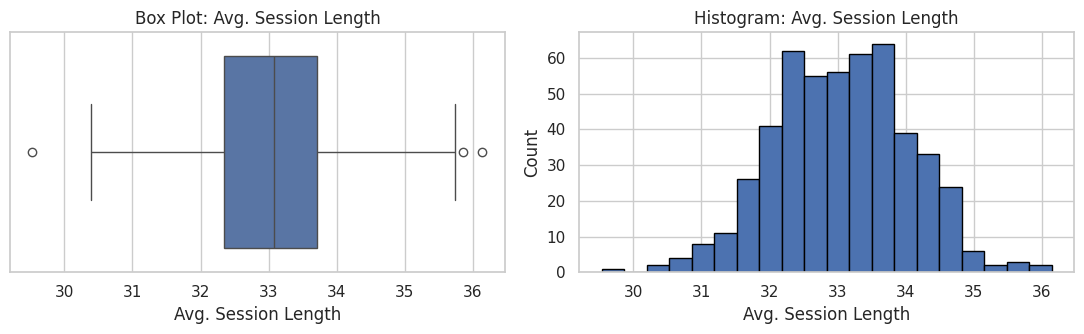

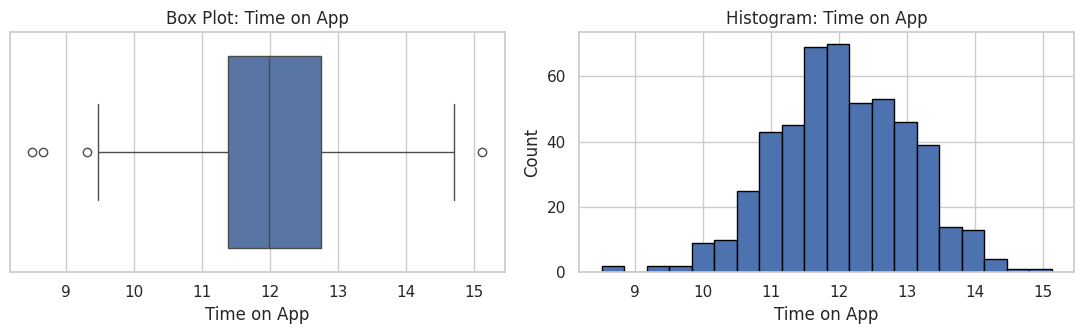

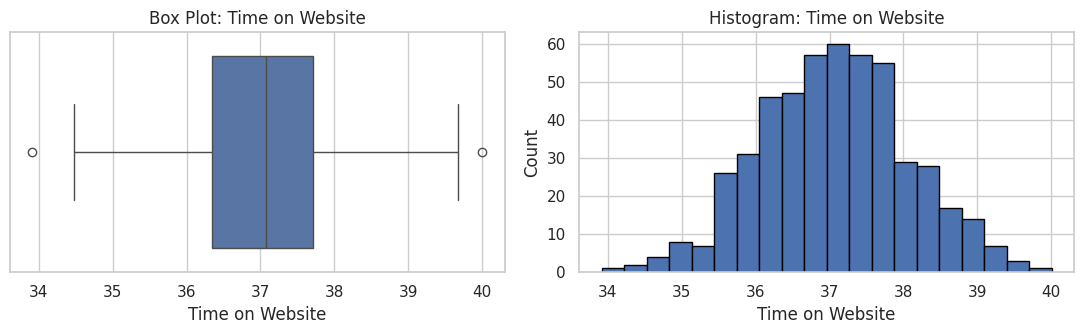

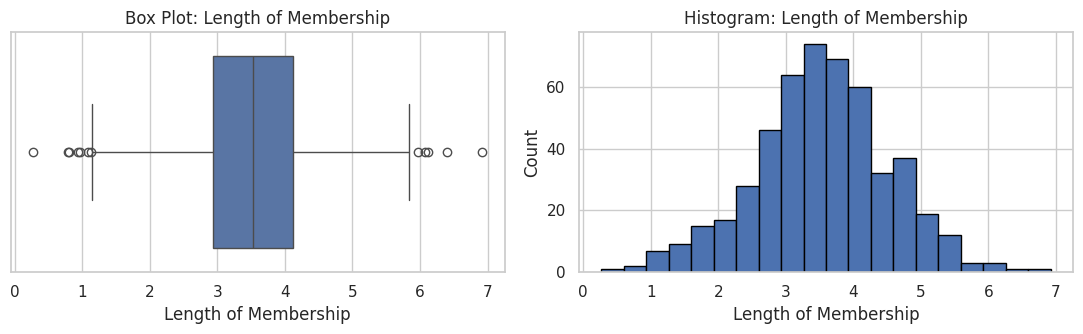

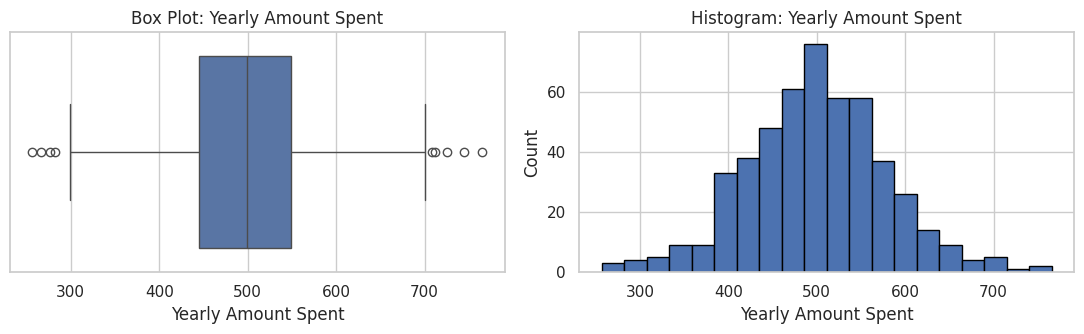

,column,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count
0,Time on App,11.388153,12.753850,1.365696,9.339609,14.802394,4
1,Yearly Amount Spent,445.038277,549.313828,104.275551,288.624951,705.727153,9


Decision: retain plausible values. The IQR rule flags statistical extremes, not necessarily errors.


In [5]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    sns.boxplot(x=df[col], ax=axes[0])
    axes[0].set_title(f"Box Plot: {col}")
    axes[0].set_xlabel(col)
    axes[1].hist(df[col], bins=20, edgecolor="black")
    axes[1].set_title(f"Histogram: {col}")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Count")
    plt.tight_layout()
    plt.show()

def iqr_outlier_report(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((data[column] < lower) | (data[column] > upper)).sum()
    return {"column": column, "Q1": q1, "Q3": q3, "IQR": iqr,
            "Lower bound": lower, "Upper bound": upper, "Outlier count": int(count)}

iqr_results = pd.DataFrame([
    iqr_outlier_report(df, "Time on App"),
    iqr_outlier_report(df, "Yearly Amount Spent")
])
display(iqr_results)
print("Decision: retain plausible values. The IQR rule flags statistical extremes, not necessarily errors.")


## Step 5: Univariate analysis
Histograms and box plots are shown for every numeric column. The median represents a typical value; skewness helps describe asymmetry.

,mean,median,std,min,max,skewness
Avg. Session Length,33.053194,33.082008,0.992563,29.532429,36.139662,-0.032175
Time on App,12.052488,11.983231,0.994216,8.508152,15.126994,-0.089121
Time on Website,37.060445,37.069367,1.010489,33.913847,40.005182,0.012142
Length of Membership,3.533462,3.533975,0.999278,0.269901,6.922689,-0.106608
Yearly Amount Spent,499.314038,498.887875,79.314782,256.670582,765.518462,0.034790


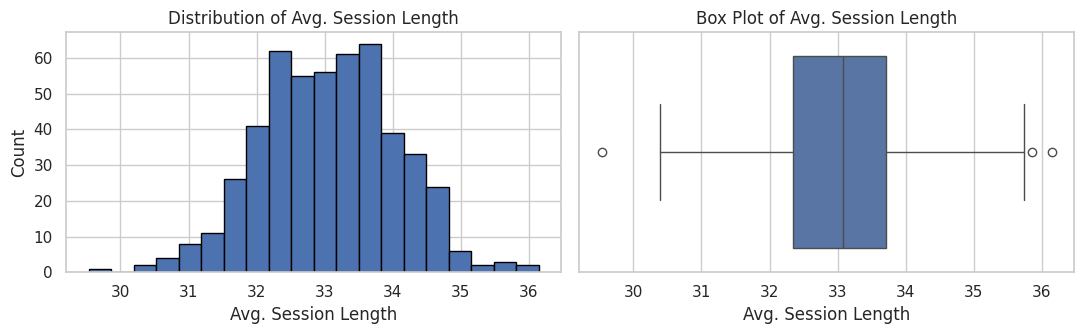

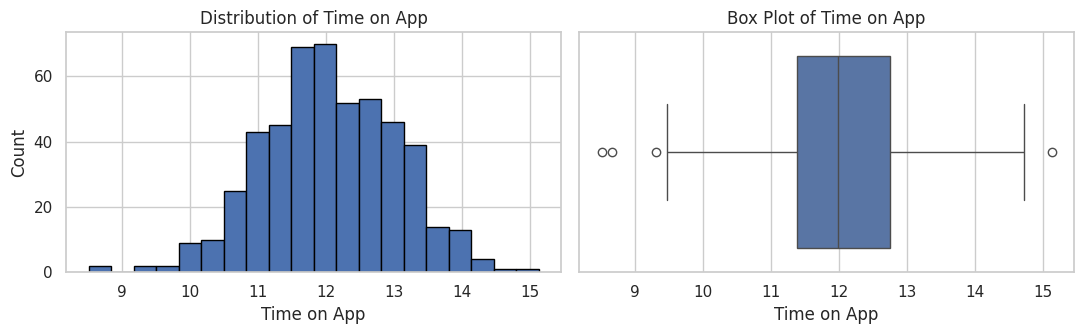

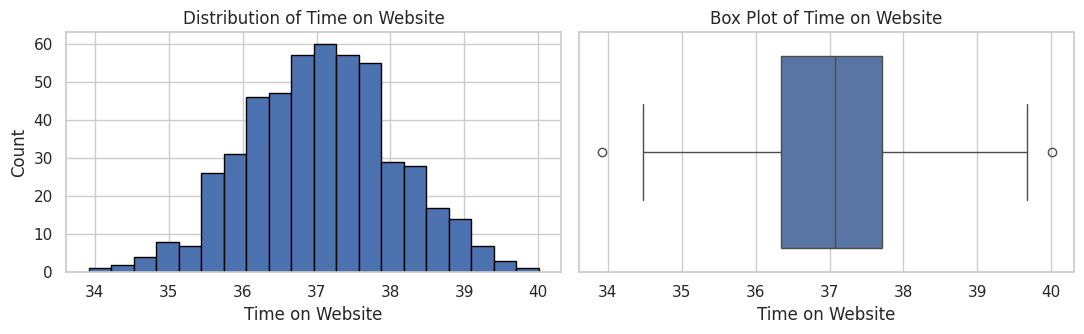

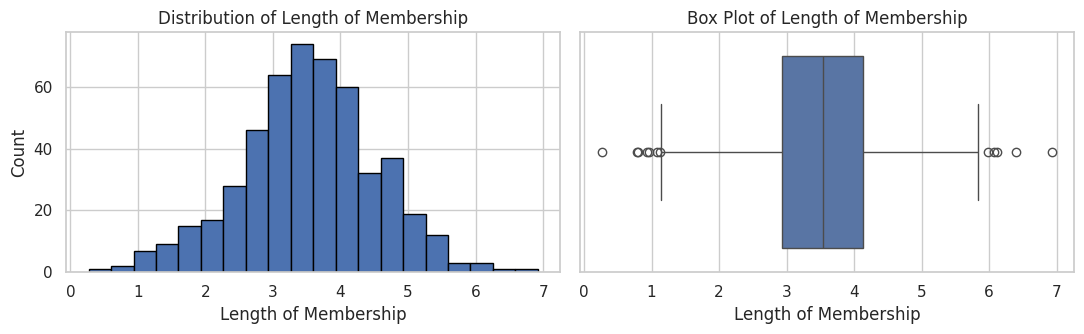

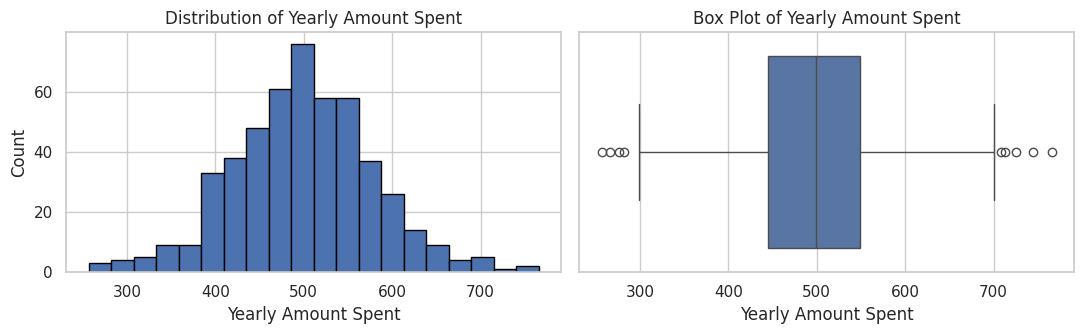

In [6]:
summary = df[numeric_cols].agg(["mean", "median", "std", "min", "max"]).T
summary["skewness"] = df[numeric_cols].skew()
display(summary)
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].hist(df[col], bins=20, edgecolor="black")
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Count")
    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"Box Plot of {col}")
    axes[1].set_xlabel(col)
    plt.tight_layout()
    plt.show()


## Step 6: Bivariate analysis
The scatter plots compare app and website engagement with yearly spending. The heatmap summarizes pairwise linear correlations among numeric columns.

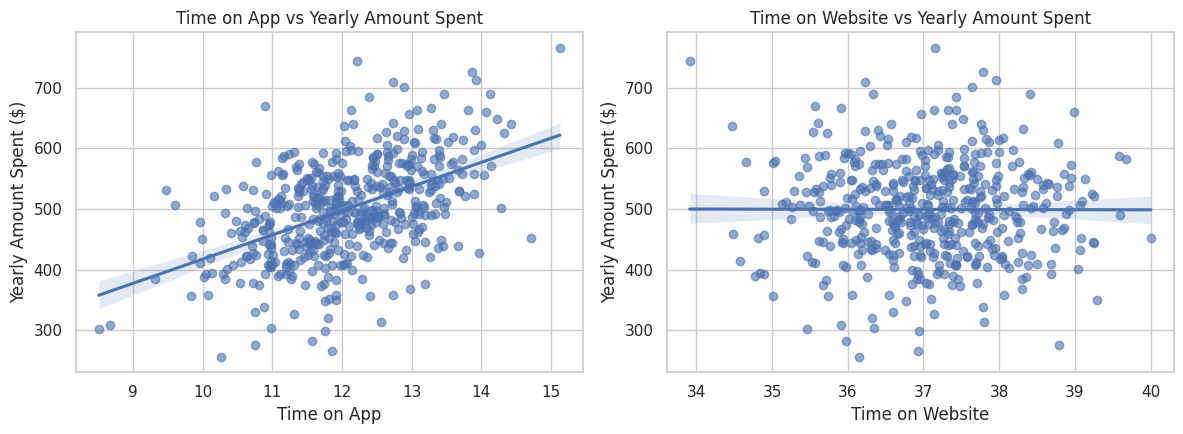

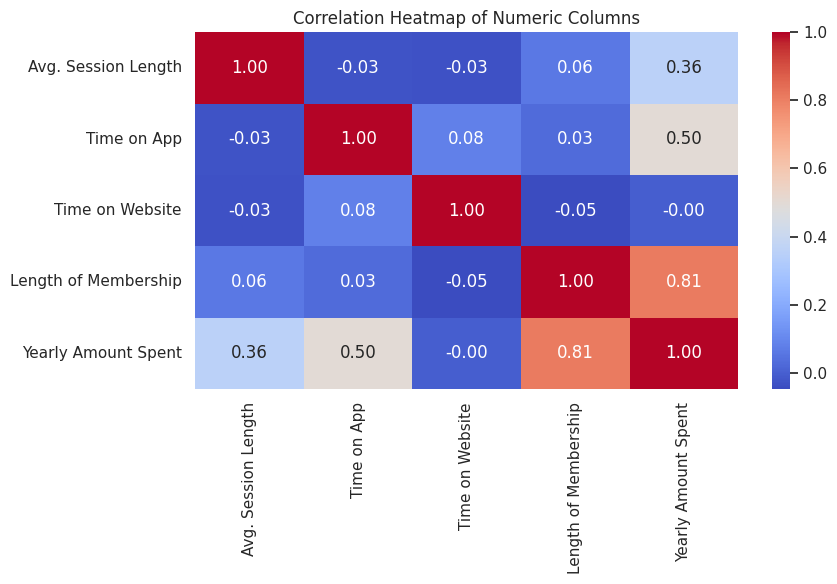

Correlation: app time vs yearly spend = 0.499
Correlation: website time vs yearly spend = -0.003
Strongest numeric relationship with yearly spend: Length of Membership (r = 0.809)
A correlation indicates association, not proof that one variable causes another.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.regplot(data=df, x="Time on App", y="Yearly Amount Spent", ax=axes[0], scatter_kws={"alpha": 0.6})
axes[0].set_title("Time on App vs Yearly Amount Spent")
axes[0].set_xlabel("Time on App")
axes[0].set_ylabel("Yearly Amount Spent ($)")
sns.regplot(data=df, x="Time on Website", y="Yearly Amount Spent", ax=axes[1], scatter_kws={"alpha": 0.6})
axes[1].set_title("Time on Website vs Yearly Amount Spent")
axes[1].set_xlabel("Time on Website")
axes[1].set_ylabel("Yearly Amount Spent ($)")
plt.tight_layout()
plt.show()

corr = df[numeric_cols].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Columns")
plt.tight_layout()
plt.show()

app_corr = df["Time on App"].corr(df["Yearly Amount Spent"])
web_corr = df["Time on Website"].corr(df["Yearly Amount Spent"])
strongest = corr["Yearly Amount Spent"].drop("Yearly Amount Spent").abs().idxmax()
print(f"Correlation: app time vs yearly spend = {app_corr:.3f}")
print(f"Correlation: website time vs yearly spend = {web_corr:.3f}")
print(f"Strongest numeric relationship with yearly spend: {strongest} (r = {corr.loc[strongest, 'Yearly Amount Spent']:.3f})")
print("A correlation indicates association, not proof that one variable causes another.")


## Step 7: Answers to the eight analysis questions
Each question below has a corresponding graph or table and a written interpretation.

,Avg. Session Length
count,500.000000
mean,33.053194
std,0.992563
min,29.532429
25%,32.341822
50%,33.082008
75%,33.711985
max,36.139662


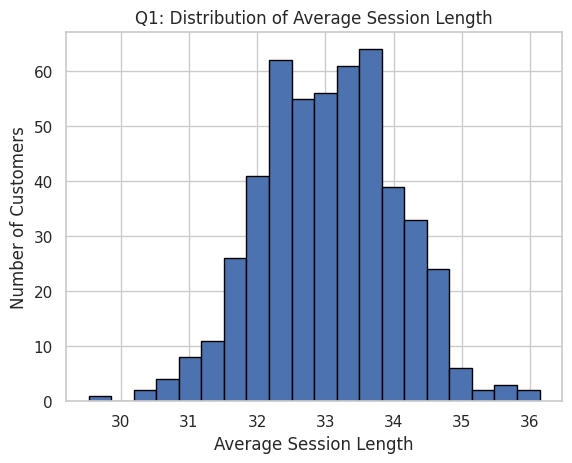

Typical (median) average session length: 33.08; skewness: -0.03.


,Time on App
count,500.000000
mean,12.052488
std,0.994216
min,8.508152
25%,11.388153
50%,11.983231
75%,12.753850
max,15.126994


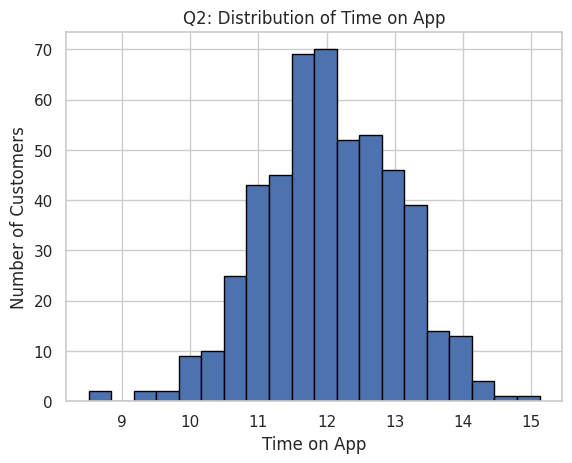

Typical (median) app time: 11.98; skewness: -0.09.


,Yearly Amount Spent
count,500.000000
mean,499.314038
std,79.314782
min,256.670582
25%,445.038277
50%,498.887875
75%,549.313828
max,765.518462


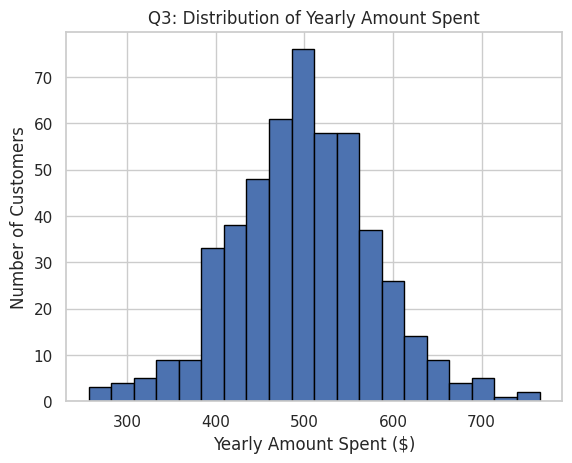

Typical (median) yearly spend: $498.89; skewness: 0.03.


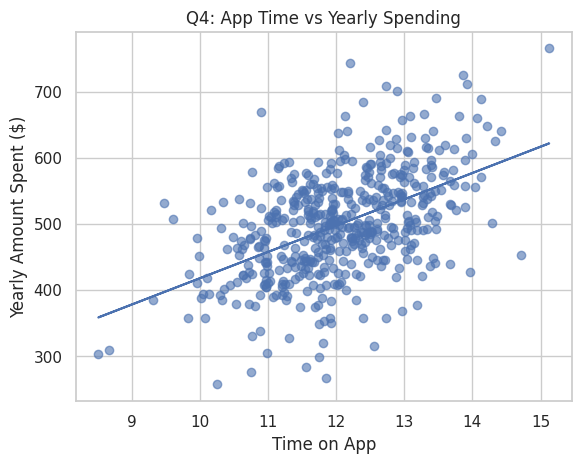

App time and yearly spend have correlation r = 0.499.


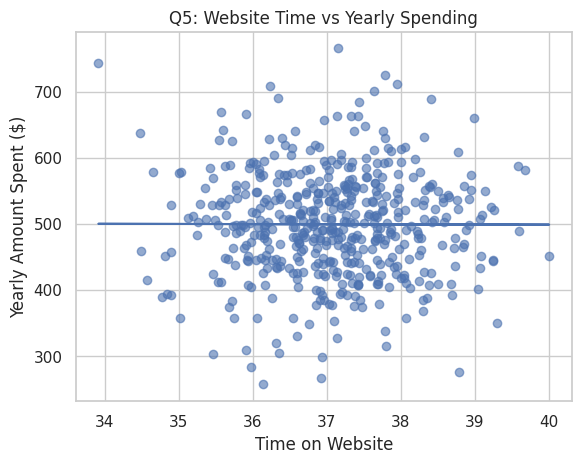

Website time and yearly spend have correlation r = -0.003.


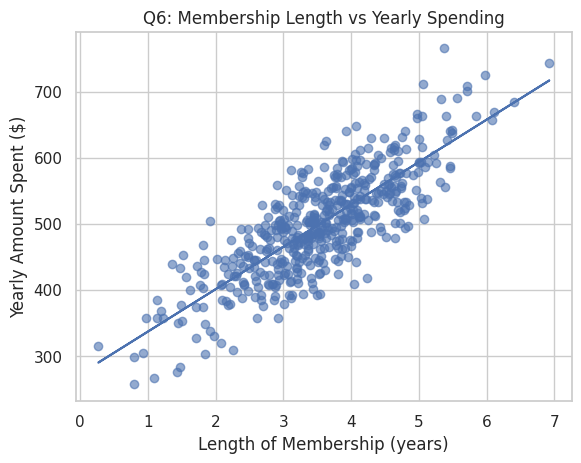

Membership length and yearly spend have correlation r = 0.809.


,Channel,Average time,Correlation with yearly spend
0,App,12.052488,0.499328
1,Website,37.060445,-0.002641


App time has the stronger absolute correlation with yearly spending in this dataset.


,Customer,Yearly Amount Spent,Length of Membership
65,Customer 1,765.518462,5.377594
157,Customer 2,744.221867,6.922689
50,Customer 3,725.584814,5.976768
205,Customer 4,712.396327,5.066697
368,Customer 5,708.935185,5.705941
24,Customer 6,700.917092,5.705154
305,Customer 7,689.787604,5.566385
464,Customer 8,689.235700,5.320094
151,Customer 9,684.163431,6.401229
396,Customer 10,669.987141,6.115199


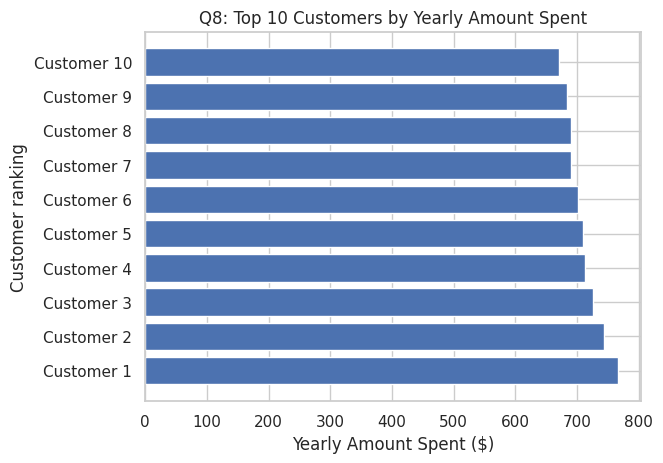

In [8]:
# Q1. Distribution of average session length
display(df["Avg. Session Length"].describe().to_frame("Avg. Session Length"))
plt.hist(df["Avg. Session Length"], bins=20, edgecolor="black")
plt.title("Q1: Distribution of Average Session Length")
plt.xlabel("Average Session Length")
plt.ylabel("Number of Customers")
plt.show()
print(f"Typical (median) average session length: {df['Avg. Session Length'].median():.2f}; skewness: {df['Avg. Session Length'].skew():.2f}.")

# Q2. Distribution of time on app
display(df["Time on App"].describe().to_frame("Time on App"))
plt.hist(df["Time on App"], bins=20, edgecolor="black")
plt.title("Q2: Distribution of Time on App")
plt.xlabel("Time on App")
plt.ylabel("Number of Customers")
plt.show()
print(f"Typical (median) app time: {df['Time on App'].median():.2f}; skewness: {df['Time on App'].skew():.2f}.")

# Q3. Distribution of yearly spend
display(df["Yearly Amount Spent"].describe().to_frame("Yearly Amount Spent"))
plt.hist(df["Yearly Amount Spent"], bins=20, edgecolor="black")
plt.title("Q3: Distribution of Yearly Amount Spent")
plt.xlabel("Yearly Amount Spent ($)")
plt.ylabel("Number of Customers")
plt.show()
print(f"Typical (median) yearly spend: ${df['Yearly Amount Spent'].median():.2f}; skewness: {df['Yearly Amount Spent'].skew():.2f}.")

# Q4. App time and spend
plt.scatter(df["Time on App"], df["Yearly Amount Spent"], alpha=0.6); m, b = np.polyfit(df["Time on App"], df["Yearly Amount Spent"], 1); plt.plot(df["Time on App"], m*df["Time on App"]+b)
plt.title("Q4: App Time vs Yearly Spending")
plt.xlabel("Time on App")
plt.ylabel("Yearly Amount Spent ($)")
plt.show()
print(f"App time and yearly spend have correlation r = {app_corr:.3f}.")

# Q5. Website time and spend
plt.scatter(df["Time on Website"], df["Yearly Amount Spent"], alpha=0.6); m, b = np.polyfit(df["Time on Website"], df["Yearly Amount Spent"], 1); plt.plot(df["Time on Website"], m*df["Time on Website"]+b)
plt.title("Q5: Website Time vs Yearly Spending")
plt.xlabel("Time on Website")
plt.ylabel("Yearly Amount Spent ($)")
plt.show()
print(f"Website time and yearly spend have correlation r = {web_corr:.3f}.")

# Q6. Membership length and spend
membership_corr = df["Length of Membership"].corr(df["Yearly Amount Spent"])
plt.scatter(df["Length of Membership"], df["Yearly Amount Spent"], alpha=0.6); m, b = np.polyfit(df["Length of Membership"], df["Yearly Amount Spent"], 1); plt.plot(df["Length of Membership"], m*df["Length of Membership"]+b)
plt.title("Q6: Membership Length vs Yearly Spending")
plt.xlabel("Length of Membership (years)")
plt.ylabel("Yearly Amount Spent ($)")
plt.show()
print(f"Membership length and yearly spend have correlation r = {membership_corr:.3f}.")

# Q7. App vs website comparison
channel_comparison = pd.DataFrame({
    "Channel": ["App", "Website"],
    "Average time": [df["Time on App"].mean(), df["Time on Website"].mean()],
    "Correlation with yearly spend": [app_corr, web_corr]
})
display(channel_comparison)
best_channel = "App" if abs(app_corr) > abs(web_corr) else "Website"
print(f"{best_channel} time has the stronger absolute correlation with yearly spending in this dataset.")

# Q8. Top 10 customers by yearly spend (email masked in the displayed ranking)
top10 = df.nlargest(10, "Yearly Amount Spent")[["Email", "Yearly Amount Spent", "Length of Membership"]].copy()
top10["Customer"] = [f"Customer {i+1}" for i in range(len(top10))]
top10_display = top10[["Customer", "Yearly Amount Spent", "Length of Membership"]]
display(top10_display)
plt.barh(top10_display["Customer"], top10_display["Yearly Amount Spent"])
plt.title("Q8: Top 10 Customers by Yearly Amount Spent")
plt.xlabel("Yearly Amount Spent ($)")
plt.ylabel("Customer ranking")
plt.show()


## Step 8: Conclusion
The following summary is generated from the dataset's actual statistics and can be edited after reviewing the graphs.

In [9]:
print(
    f"1. The dataset contains {len(df)} customer records and {df.shape[1]} columns.\n"
    f"2. Average yearly amount spent is ${df['Yearly Amount Spent'].mean():.2f}, "
    f"with a median of ${df['Yearly Amount Spent'].median():.2f}.\n"
    f"3. App-time correlation with yearly spending is {app_corr:.2f}.\n"
    f"4. Website-time correlation with yearly spending is {web_corr:.2f}.\n"
    f"5. Membership length correlation with yearly spending is {membership_corr:.2f}.\n"
    f"6. Suggestion: test improvements to {best_channel.lower()} experience and track whether customer engagement and spending change over time."
)


1. The dataset contains 500 customer records and 8 columns.
2. Average yearly amount spent is $499.31, with a median of $498.89.
3. App-time correlation with yearly spending is 0.50.
4. Website-time correlation with yearly spending is -0.00.
5. Membership length correlation with yearly spending is 0.81.
6. Suggestion: test improvements to app experience and track whether customer engagement and spending change over time.
